In [30]:
import pandas as pd
import numpy as np
from functions import read_squid_file
from functions import determine_critical_temp
from functions import determine_critical_field
import matplotlib.pyplot as plt
import os
import statistics

In [31]:
# should functionise this
#=======================================================================
# matplotlib rc — academic / journal style
#=======================================================================
plt.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.labelsize":    10,
    "axes.titlesize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size":  4.0,
    "ytick.major.size":  4.0,
    "xtick.minor.size":  2.0,
    "ytick.minor.size":  2.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "axes.grid":         True,
    "grid.color":        "#CCCCCC",
    "grid.linewidth":    0.4,
    "grid.linestyle":    "--",
    "grid.alpha":        0.6,
    "axes.axisbelow":    True,
    "figure.facecolor":  "white",
    "figure.figsize":    [7,4],
    "axes.facecolor":    "white",
    "savefig.dpi":       600,
    "savefig.bbox":      "tight",
    "savefig.facecolor": "white",
    "figure.dpi":        150,
    "legend.framealpha": 0.9,
    "legend.edgecolor":  "#AAAAAA",
    "legend.frameon":    True,
})

In [32]:
# Source - https://stackoverflow.com/a/10378012
# Posted by anselm, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-15, License - CC BY-SA 4.0
# edited by ben thomposn



print("="*40)
print("FIELD COOLING")
print("="*40)
from pathlib import Path
runs_fc = {}
pathlist = Path(
    "data/2026/10/FeSe_bo001_MvsT_FC_VariousFields"
).glob("**/*.dat")
for path in sorted(pathlist):
    run_number = path.stem[-5:]
    runs_fc[run_number] = read_squid_file(str(path))
for run_number, data in runs_fc.items():
    print(f"Run {run_number}")

print("="*40)
print("FIELD WARMING")
print("="*40)



from pathlib import Path
runs_fw = {}
pathlist = Path(
    "data/2026/10/FeSe_bo001_MvsT_FW_VariousFields"
).glob("**/*.dat")
for path in sorted(pathlist):
    run_number = path.stem[-5:]
    runs_fw[run_number] = read_squid_file(str(path))
for run_number, data in runs_fw.items():
    print(f"Run {run_number}")




FIELD COOLING
Run 00001
Run 00002
Run 00003
Run 00004
FIELD WARMING
Run 00001
Run 00002
Run 00003
Run 00004
Run 00005


In [33]:
runs_fc.items()

dict_items([('00001',      Time Stamp (sec)  Temperature (K)  Magnetic Field (Oe)  Moment (emu)  \
0        4.001872e+09        13.002908             9.543491           NaN   
1        4.001872e+09        12.987748             9.543491           NaN   
2        4.001872e+09        12.974274             9.543491           NaN   
3        4.001872e+09        12.957255             9.543491           NaN   
4        4.001872e+09        12.941221             9.543491           NaN   
..                ...              ...                  ...           ...   
590      4.001875e+09         4.001787             9.543491           NaN   
591      4.001875e+09         4.003026             9.543491           NaN   
592      4.001875e+09         4.002380             9.543491           NaN   
593      4.001875e+09         4.004627             9.543491           NaN   
594      4.001875e+09         4.002986             9.543491           NaN   

     M. Std. Err. (emu)  Transport Action  Center Pos

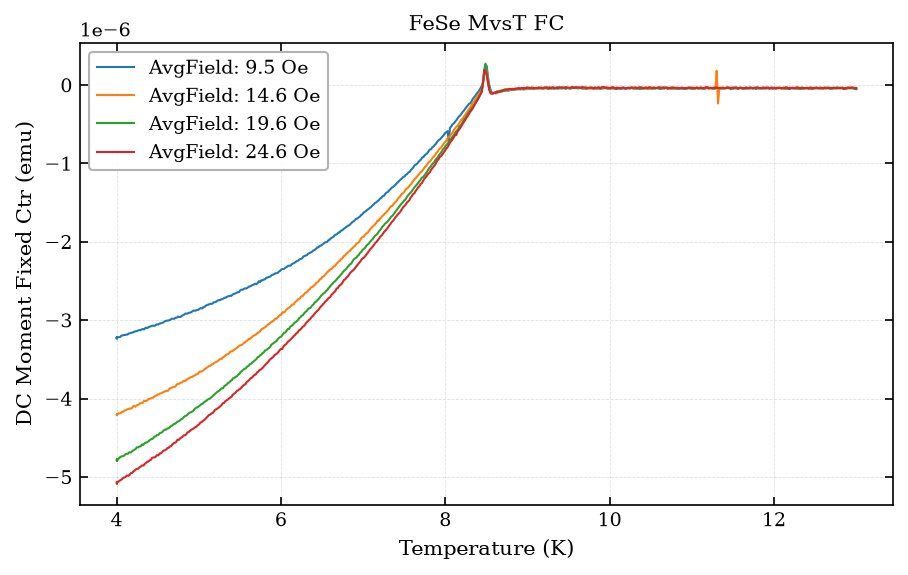

In [34]:
# ========================================
# FIELD COOLING
# ========================================
for run_number, dataframe in runs_fc.items():
    field = np.mean(dataframe["Magnetic Field (Oe)"])
    crit_temp, fitted_line, _ = determine_critical_temp(dataframe)
    # plt.axvline(crit_temp, color="tab:grey", linestyle="--", label=f"{crit_temp:.3f} K")
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgField: {field:.1f} Oe",
    )
    
plt.title("FeSe MvsT FC")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.show()

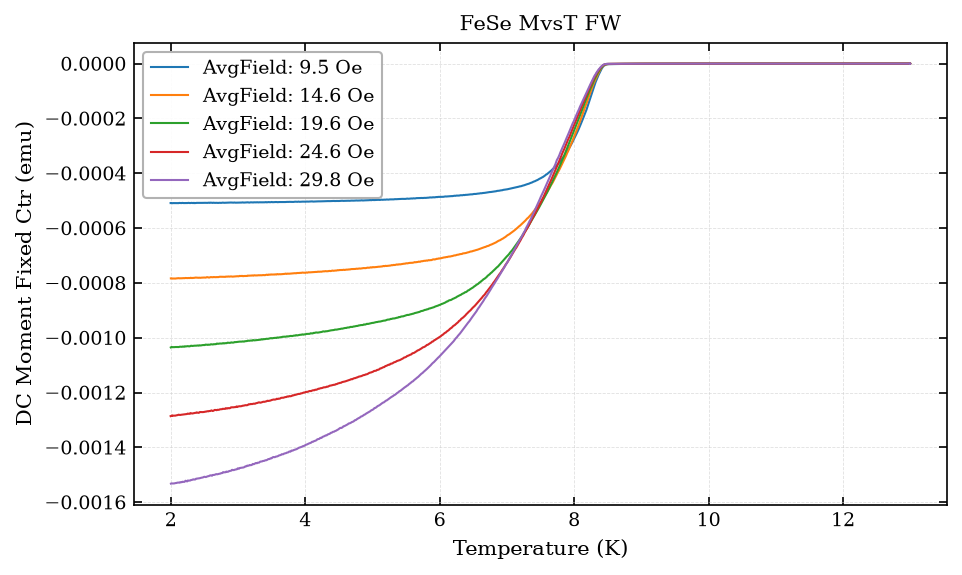

In [35]:
# ========================================
# FIELD WARMING
# ========================================
for run_number, dataframe in runs_fw.items():
    field = np.mean(dataframe["Magnetic Field (Oe)"])
    crit_temp, fitted_line, _ = determine_critical_temp(dataframe)
    # plt.axvline(crit_temp, color="tab:grey", linestyle="--", label=f"{crit_temp:.3f} K")
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgField: {field:.1f} Oe",
    )
    
plt.title("FeSe MvsT FW")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.show()

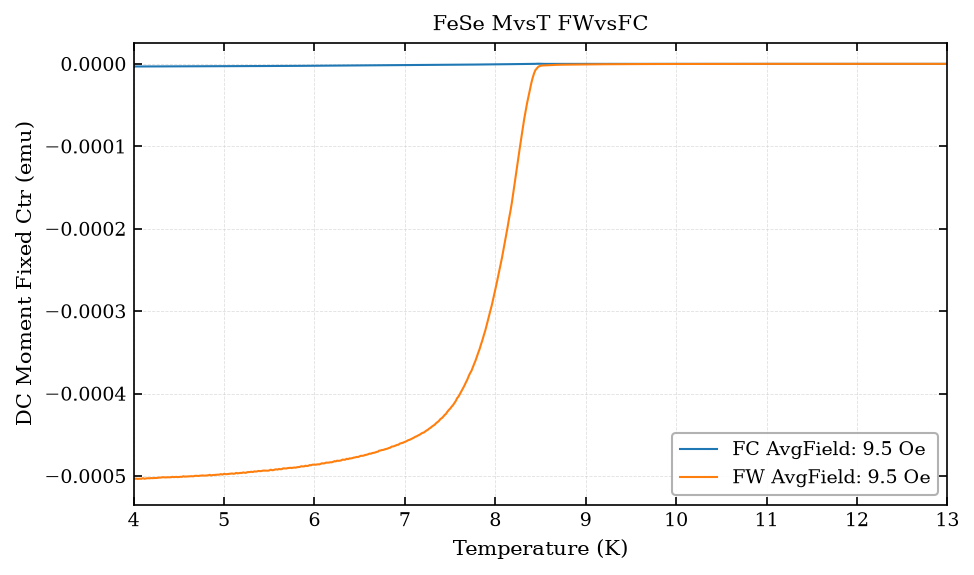

In [36]:
# FC selecting one run for FeSe
run00001_fc = runs_fc["00001"]
field_fc = np.mean(run00001_fc["Magnetic Field (Oe)"])

# FW selecting one run for FeSe
run00001_fw = runs_fw["00001"]
field_fw = np.mean(run00001_fw["Magnetic Field (Oe)"])

# Plotting For comparison
plt.plot(
    run00001_fc["Temperature (K)"],
    run00001_fc["DC Moment Fixed Ctr (emu)"],
    label=f"FC AvgField: {field_fc:.1f} Oe",
)
plt.title("FeSe MvsT FWvsFC")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()

plt.plot(
    run00001_fw["Temperature (K)"],
    run00001_fw["DC Moment Fixed Ctr (emu)"],
    label=f"FW AvgField: {field_fw:.1f} Oe",
)
    
plt.title("FeSe MvsT FWvsFC")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.xlim(4,13)
plt.legend()
plt.savefig("fese_mvst_9p5oe_fig8.svg", transparent=True, dpi=600)

plt.show()

# Lead for comparison

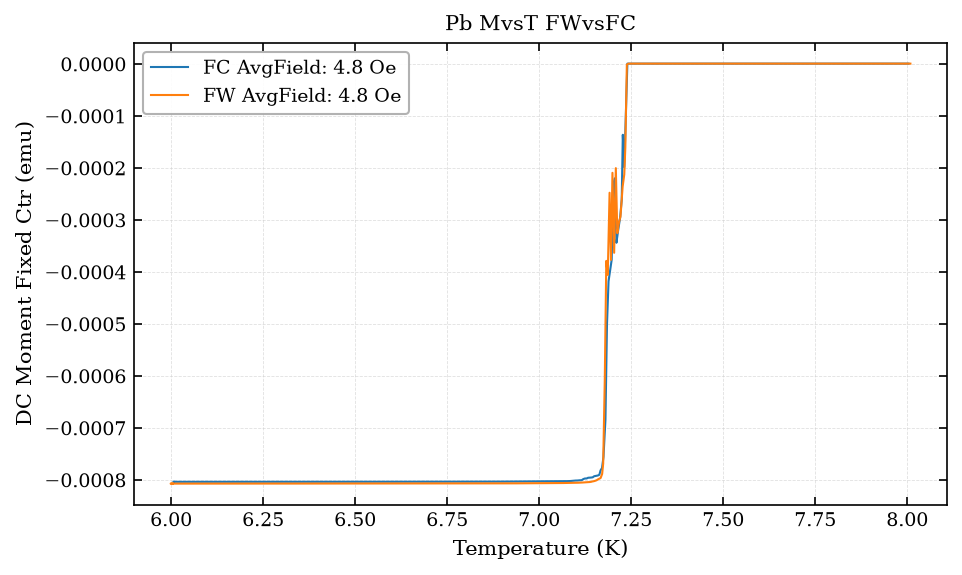

In [37]:
# get field warming
pb_fw = read_squid_file("data/2026/10/misc/2026-10-14 Pb MvsT FW 5Oe.dat")
field_fw = np.mean(pb_fw["Magnetic Field (Oe)"])
# get field cooling 

pb_fc = read_squid_file("data/2026/10/misc/2026-10-14 Pb MvsT FC 5Oe.dat")
field_fc = np.mean(pb_fc["Magnetic Field (Oe)"])

# Plotting For comparison
plt.plot(
    pb_fc["Temperature (K)"],
    pb_fc["DC Moment Fixed Ctr (emu)"],
    label=f"FC AvgField: {field_fc:.1f} Oe",
)
plt.title("FeSe MvsT FWvsFC")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()

plt.plot(
    pb_fw["Temperature (K)"],
    pb_fw["DC Moment Fixed Ctr (emu)"],
    label=f"FW AvgField: {field_fw:.1f} Oe",
)
    
plt.title("Pb MvsT FWvsFC")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.savefig("pb_mvst_4p8oe_fig9.svg", transparent=True, dpi=600)

plt.show()